# Exploratory Data Analysis

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load data (assuming your dataset is saved as hotel_bookings.csv)
df = pd.read_csv(r'C:\Users\HP\Hotel_Cancellation_Case_Study\data\hotel_bookings_cleaned.csv')

# Set aesthetic layout
sns.set_theme(style="whitegrid")

#Phase 1: Univariate Analysis

C:\Users\HP\AppData\Local\Temp\ipykernel_13052\1091184309.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="is_canceled", palette="pastel")


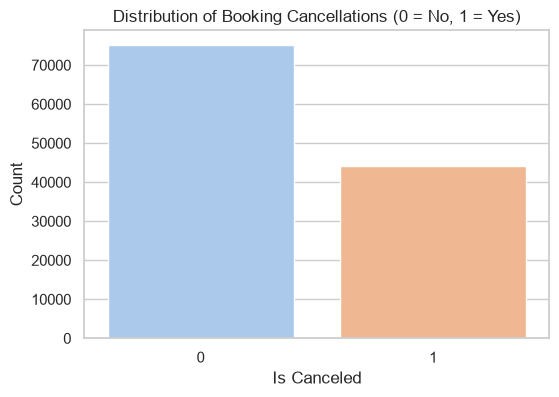

In [3]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="is_canceled", palette="pastel")
plt.title("Distribution of Booking Cancellations (0 = No, 1 = Yes)")
plt.xlabel("Is Canceled")
plt.ylabel("Count")
plt.show();

Hotel booking data reveals over 75,000 confirmed stays compared to more than 40,000 cancellations. While confirmed bookings represent the majority, a cancellation volume this high is unusual since people typically book with the intent to travel. This significant baseline suggests that multiple underlying friction factors are driving customers to cancel.

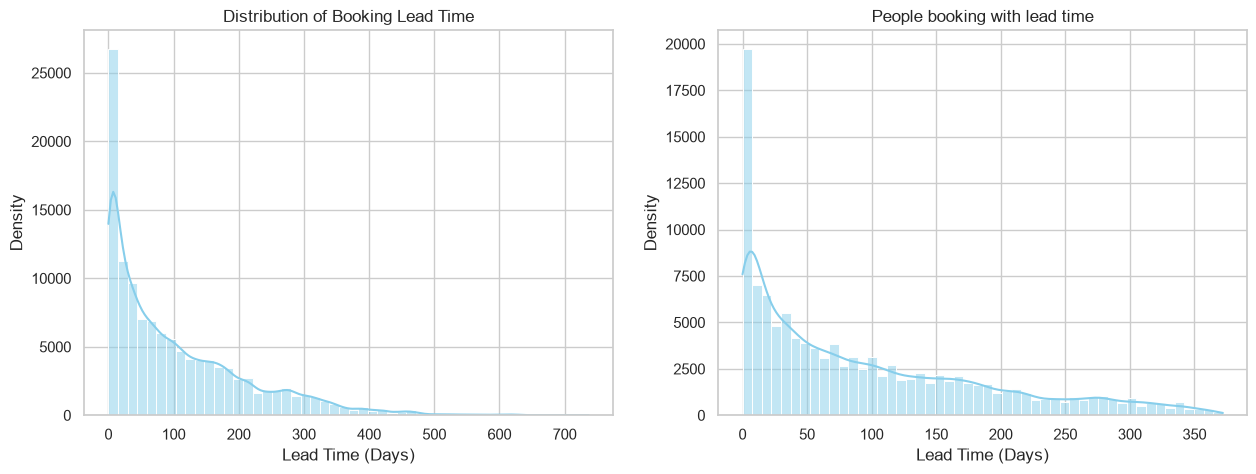

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df["lead_time"], kde=True, bins=50, color="skyblue", ax=axes[0])
axes[0].set_title("Distribution of Booking Lead Time")
axes[0].set_xlabel("Lead Time (Days)")
axes[0].set_ylabel("Density")


import numpy as np
Q1 = np.percentile(df['lead_time'], 25)
Q3 = np.percentile(df['lead_time'], 75)
df1 = df[df['lead_time'] < Q3 + 1.5 * (Q3 - Q1)]
sns.histplot(data=df1, x="lead_time", kde=True, bins=50, color="skyblue", ax=axes[1])
axes[1].set_title('People booking with lead time')
axes[1].set_xlabel("Lead Time (Days)")
axes[1].set_ylabel("Density")
plt.show()


The first plot clearly shows that while most bookings occur within 0 to 100 days, a tiny fraction of extreme bookings stretches out to 400–650 days, heavily compressing the main distribution. By applying the IQR rule to filter these outliers, your second plot successfully "zooms in" on the core customer behavior, providing a much clearer and more detailed view of the true booking density without the visual noise.

In [52]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_nights
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,1
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,1
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03,2


C:\Users\HP\AppData\Local\Temp\ipykernel_13052\2355551415.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="arrival_date_year", palette="muted", ax=axes[0])


Text(0.5, 1.0, 'Booking Cancellations by Year')

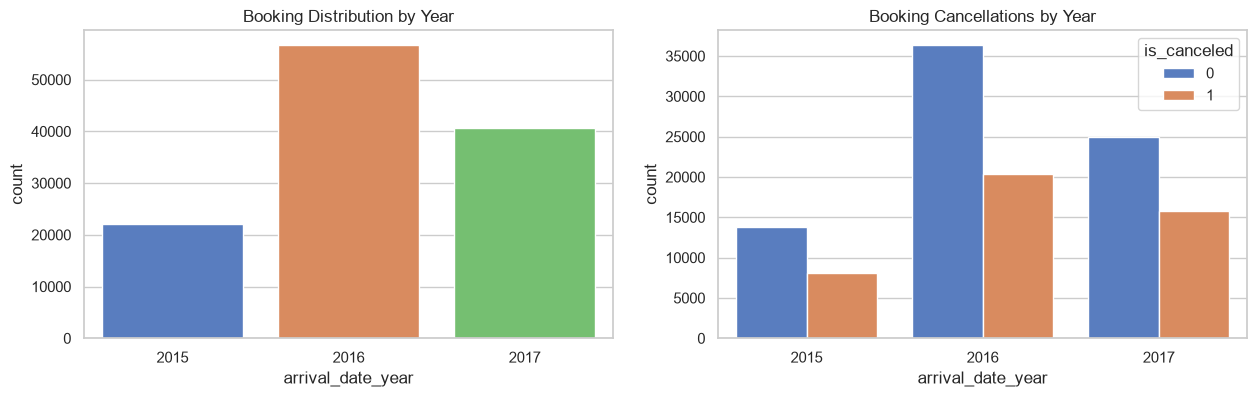

In [18]:
fig,axes = plt.subplots(1, 2, figsize=(15, 4))

sns.countplot(data=df, x="arrival_date_year", palette="muted", ax=axes[0])
axes[0].set_title("Booking Distribution by Year")

sns.countplot(data=df, x="arrival_date_year", hue='is_canceled', palette="muted", ax=axes[1])
axes[1].set_title("Booking Cancellations by Year")


<Axes: xlabel='arrival_date_year', ylabel='count'>

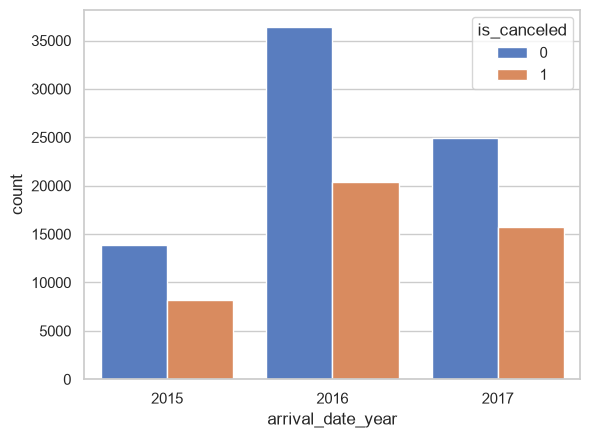

In [12]:
sns.countplot(data=df, x="arrival_date_year", hue='is_canceled', palette="muted")

#Multivariate Analysis

C:\Users\HP\AppData\Local\Temp\ipykernel_1096\3681633914.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\HP\AppData\Local\Temp\ipykernel_1096\3681633914.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


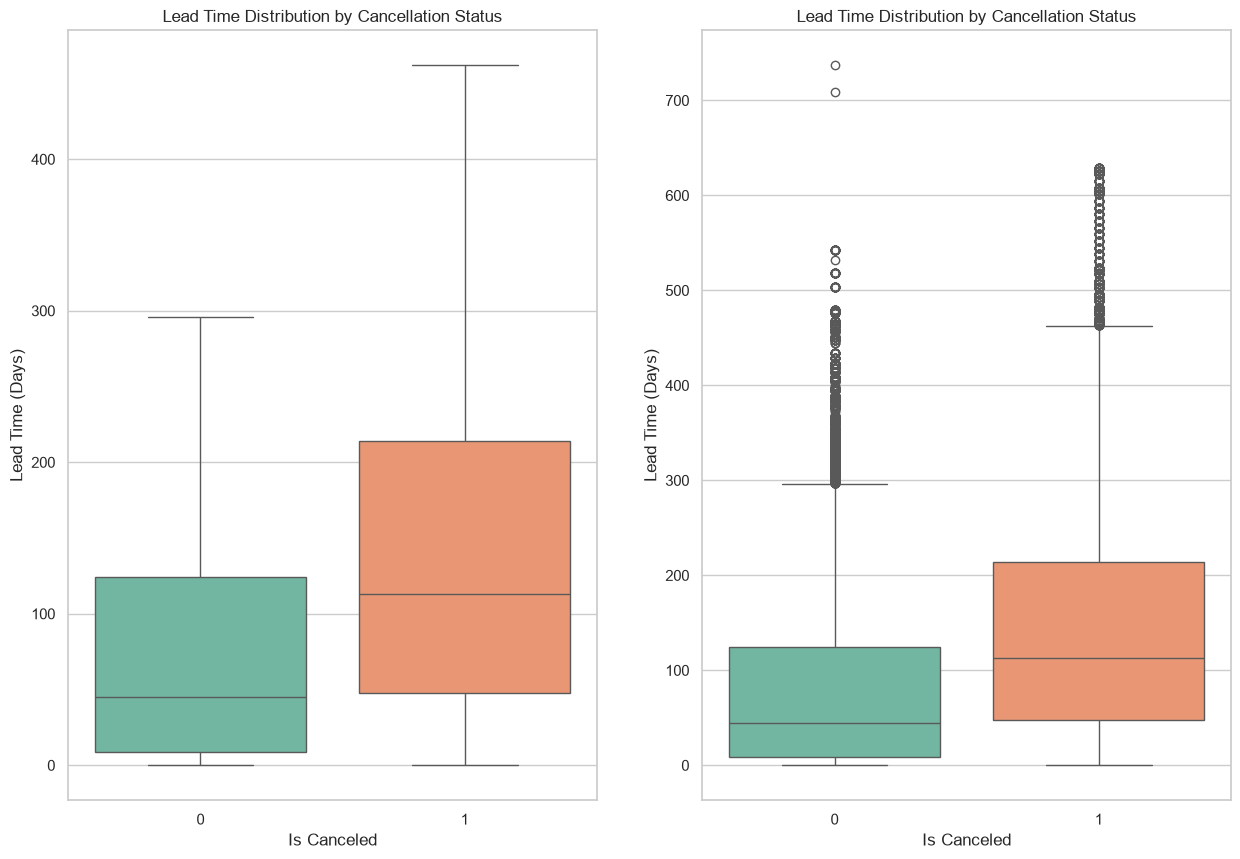

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 10))

sns.boxplot(
    data=df, x="is_canceled", y="lead_time", showfliers=False, palette="Set2",ax=ax1
)
ax1.set_title("Lead Time Distribution by Cancellation Status")
ax1.set_xlabel("Is Canceled")
ax1.set_ylabel("Lead Time (Days)")

sns.boxplot(
    data=df, x="is_canceled", y="lead_time", showfliers=True, palette="Set2",ax=ax2
)
ax2.set_title("Lead Time Distribution by Cancellation Status")
ax2.set_xlabel("Is Canceled")
ax2.set_ylabel("Lead Time (Days)");

Shorter lead times (0 to 150 days) represent firm plans with a low probability of cancellation, showing much tighter variation on a box plot. In contrast, longer lead times introduce uncertainty, resulting in frequent cancellations and higher variation. While non-cancellation outliers rarely stretch past 300 to 500 days, cancellation outliers extend much further into extreme lead times—meaning that once a booking exceeds this threshold, the likelihood of it being cancelled increases dramatically.

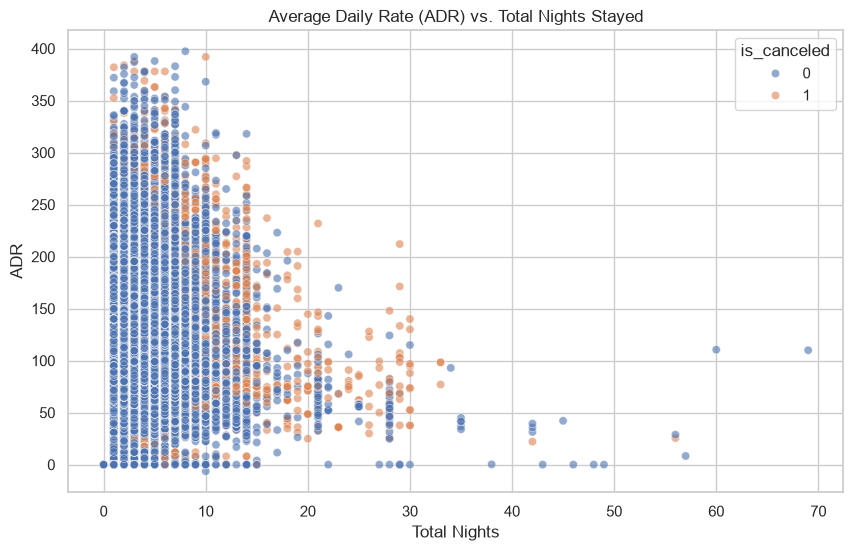

In [16]:
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]

plt.figure(figsize=(10, 6))
# Filter out extreme ADR outliners for clearer visualization
sns.scatterplot(
    data=df[df["adr"] < 400],
    x="total_nights",
    y="adr",
    hue="is_canceled",
    alpha=0.6,
)
plt.title("Average Daily Rate (ADR) vs. Total Nights Stayed")
plt.xlabel("Total Nights")
plt.ylabel("ADR")
plt.show()


A distinct pattern emerges when comparing total nights stayed against the Average Daily Rate (ADR). Bookings that exceed 10 nights show a high frequency of cancellations.

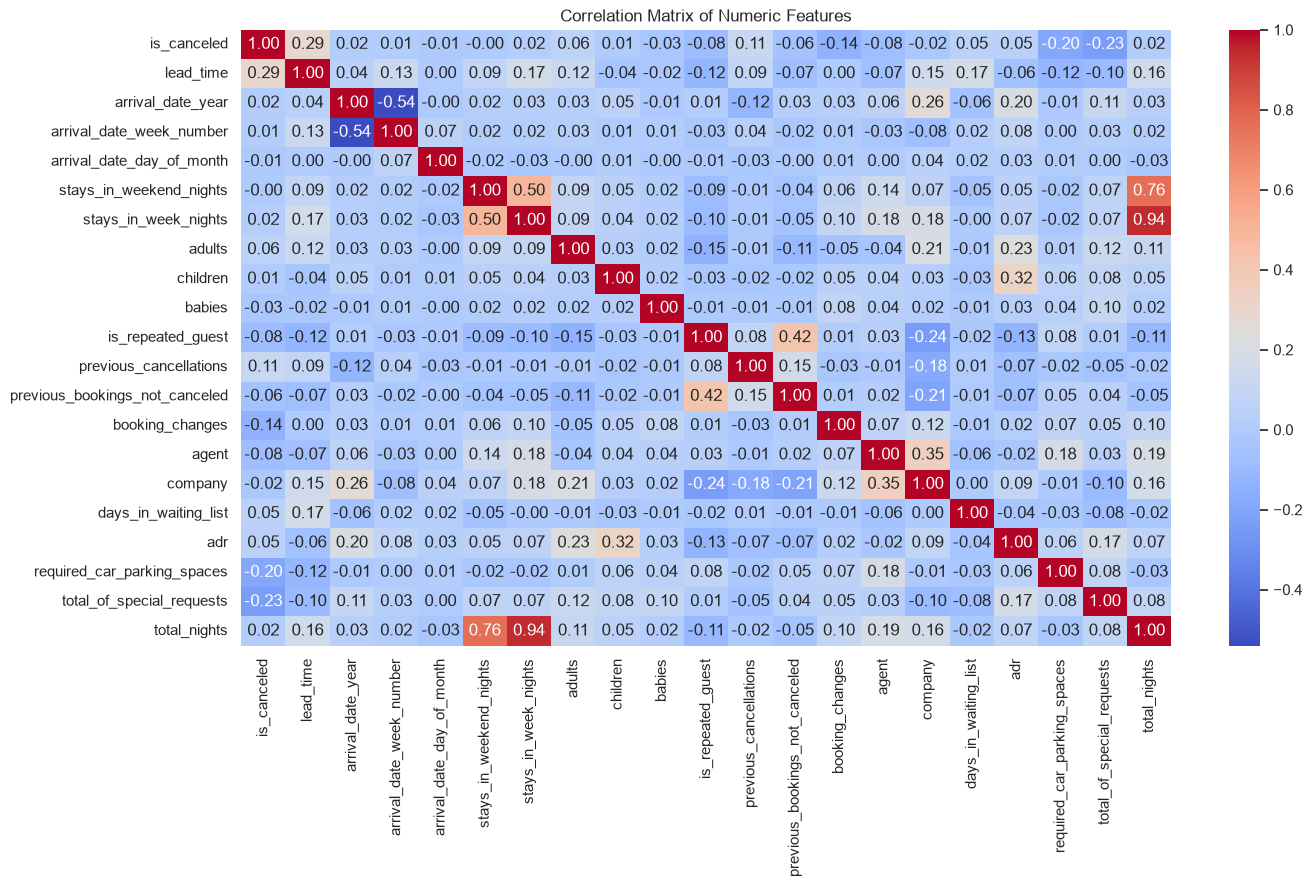

In [18]:
plt.figure(figsize=(15, 8))
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix of Numeric Features")
plt.show()



1. The Core Metrics of "Total Nights Stayed"

• total_nights vs. stays_in_week_nights (0.94) & stays_in_weekend_nights (0.76): These extremely high positive numbers are expected because total_nights is directly calculated from them.

• total_nights vs. lead_time (0.16): There is a small, weak positive correlation here. It suggests that guests who plan to stay for longer durations tend to book their rooms slightly further in advance compared to short-stay guests.

2. Key Insights for Cancellations (is_canceled)

• is_canceled vs. lead_time (0.29): This is one of the strongest positive indicators for cancellations in the dataset. It means that the earlier a booking is made (higher lead time), the more likely it is to be canceled.

• is_canceled vs. total_special_requests (-0.23): This negative relationship indicates that guests who make special requests (like asking for a high floor or a twin bed) are significantly less likely to cancel. They are more invested in their specific booking.

• is_canceled vs. required_car_parking_spaces (-0.20): Another negative relationship. Guests who explicitly request a parking spot almost never cancel their trips.

3. Customer Loyalty and Repeat Bookings

• is_repeated_guest vs. previous_bookings_not_canceled (0.42): There is a moderate positive correlation here. Regular, returning customers have a solid track record of completing their stays without canceling.

• is_repeated_guest vs. previous_cancellations (0.08): Notice that this value is very close to 0. A repeat guest isn't necessarily protected from having canceled a room in the past, but they are much more strongly associated with successful, completed stays.

4. Price & Guest Demographics (adr)

• adr (Average Daily Rate) vs. adults (0.23) & children (0.32): The price of the room increases when more people—especially children—are added to the booking.

• adr vs. is_repeated_guest (-0.13): A weak negative correlation. This could imply that returning loyal customers are being offered special discounts or lower corporate rates.

<Axes: xlabel='customer_type', ylabel='count'>

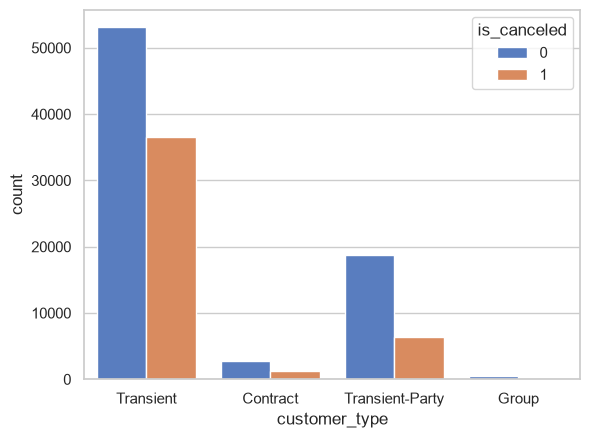

In [31]:
sns.countplot(data=df, x="customer_type", hue='is_canceled', palette="muted")

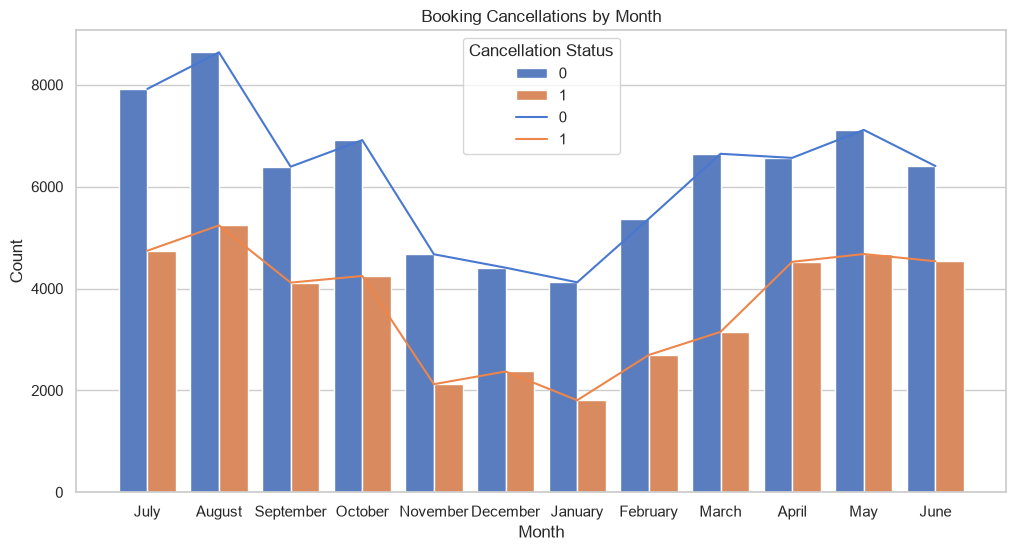

In [28]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x="arrival_date_month", hue='is_canceled', palette="muted")
sns.lineplot(data=df, x="arrival_date_month", y="is_canceled", hue='is_canceled', palette="muted", estimator='count', errorbar=None)
plt.title("Booking Cancellations by Month")
plt.xlabel("Month")
plt.ylabel("Count")
plt.legend(title="Cancellation Status")
plt.show();

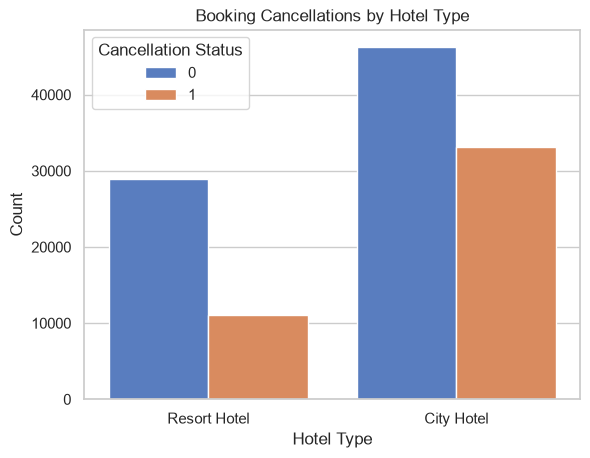

In [33]:
sns.countplot(data=df, x="hotel", hue='is_canceled', palette="muted")
plt.title("Booking Cancellations by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Count")
plt.legend(title="Cancellation Status")
plt.show();

While City Hotels bring in a much higher volume of total bookings, they also experience a significantly higher cancellation rate compared to Resort Hotels. This is a common trend since city trips are often shorter or tied to flexible business travel, whereas resort bookings usually represent major, long-planned vacations that guests are highly committed to keeping.

In [47]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_nights
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,1
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,1
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03,2


#Phase 3: Hypothesis Testing

In [21]:
from scipy import stats
from statsmodels.stats.weightstats import ttest_ind


In [23]:
t_stats, p_val, ddof = ttest_ind(canceled_lead, not_canceled_lead, value=0, alternative='two-sided')

In [24]:
print(f"T-statistic: {t_stats}, P-value: {p_val}, Degrees of Freedom: {ddof}")

T-statistic: 105.93487739055675, P-value: 0.0, Degrees of Freedom: 119388.0


Conclution:

Ho : The mean of lead time is same for cancel/not cancel the hodel bookings.

Ha : The mean of lead time is different for cancel/not cancel the hodel bookings.

- Its a two tail test.

- Independent sample test.

p value = 0.0,  P_val < 0.05 which was our standard threashold, Hence we reject the Ho.

- We have strong statistically proof to reject the Ho and conclude that mean lead time of cancel and not cancel booking is different.

- Conclution: Mean of the lead time is influencing the cancelling and non cancelling the booking.

In [25]:
from scipy.stats import chi2_contingency

In [26]:
contingency_table = pd.crosstab(df["is_canceled"], df["customer_type"])
chi2, p_val_chi2, dof, expected = stats.chi2_contingency(contingency_table)
print(f"Chi-square statistic: {chi2:.4f}, p-value: {p_val_chi2}, degrees of freedom: {dof}")

Chi-square statistic: 2222.5042, p-value: 0.0, degrees of freedom: 3


Conclution:

Ho = Booking cancellation is independent of customer segment type. 

Ha = Customer segment is significantly influencing the booking cancellation.

p_value = 0.0

- As p vale < 0.05, which was standard threshold, We will reject the Ho.

Conclution: We have strong statiscticall evidence that the Customer segment is significantly influencing the booking cancellation.


In [ ]:
# Grouping ADR array elements dynamically by room type categories
room_groups = [
    group["adr"].values
    for name, group in df.groupby("assigned_room_type")
    if len(group) > 5
]
f_stat, p_val_anova = stats.f_oneway(*room_groups)
print(f"F-statistic: {f_stat:.4f}, p-value: {p_val_anova}")


F-statistic: 1520.4850, p-value: 0.0


Conclution:

Ho = The true mean of the Average Daily Rate (adr) is identical across all assigned room types (assigned_room_type).

Ha = At least one room type exhibits a structurally distinct mean pricing layer.

- As p vale < 0.05, which was standard threshold, We will reject the Ho.

Conclution: We have strong statiscticall evidence that the At least one room type exhibits a structurally distinct mean pricing layer.

The room allocation significantly changes daily margins.

Solutions:

1. Actionable Rule: Implement a progressive deposits policy or sharper confirmation reminders for bookings placed more than 60–90 days in advance.

2. Actionable Rule: Apply strict overbooking thresholds specifically to the "Transient" bucket, while keeping group allocations rigid since group cancellations are rare but costly.